# 02 - Preprocesamiento
Deducciones de la etapa 1 - EDA

En el notebook `01_eda.ipynb` vimos que el dataset no tiene nulos ni duplicados, que las variables ya vienen entre -1 y 1 y que hay muchas variables correlacionadas.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

SEED = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 250)

## 1. Carga de datos
Además de `X` y `y`, cargamos los archivos `subject_train.txt` y `subject_test.txt`, que indican a qué persona pertenece cada ventana.

In [4]:
base = "../data"

def leer(archivo):
    return pd.read_csv(f"{base}/{archivo}", sep=r"\s+", header=None)

X_train = leer("train/X_train.txt")
X_test = leer("test/X_test.txt")
y_train = leer("train/y_train.txt")[0]
y_test = leer("test/y_test.txt")[0]
s_train = leer("train/subject_train.txt")[0]
s_test = leer("test/subject_test.txt")[0]
labels = leer("activity_labels.txt").set_index(0)[1]
nombres = leer("features.txt")[1]

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Nombres de variables repetidos:", nombres.duplicated().sum())
print(nombres[nombres.duplicated(keep=False)].head(6).tolist())

X_train: (7352, 561)  X_test: (2947, 561)
Nombres de variables repetidos: 84
['fBodyAcc-bandsEnergy()-1,8', 'fBodyAcc-bandsEnergy()-9,16', 'fBodyAcc-bandsEnergy()-17,24', 'fBodyAcc-bandsEnergy()-25,32', 'fBodyAcc-bandsEnergy()-33,40', 'fBodyAcc-bandsEnergy()-41,48']


Encontramos que `features.txt` tiene 84 nombres repetidos. Son las variables `bandsEnergy`, que se calculan para los ejes X, Y y Z pero quedaron con el mismo nombre. Como pandas necesita nombres de columna únicos, les agregamos un sufijo `_1`, `_2` a las repetidas.

In [5]:
repeticion = nombres.groupby(nombres).cumcount()
nombres_unicos = np.where(repeticion > 0, nombres + "_" + repeticion.astype(str), nombres)
print("Nombres únicos ahora:", len(set(nombres_unicos)), "de", len(nombres_unicos))

X_train.columns = nombres_unicos
X_test.columns = nombres_unicos

Nombres únicos ahora: 561 de 561


## 2. Nulos y duplicados

In [7]:
# No es necesario realizar alguna imputación de valores nulos, ya que no hay nulos en el dataset.
print("Nulos en train:", X_train.isna().sum().sum(), "| Nulos en test:", X_test.isna().sum().sum())
print("Filas duplicadas en train:", X_train.duplicated().sum(), "| en test:", X_test.duplicated().sum())
print("Columnas constantes:", (X_train.std() == 0).sum())

Nulos en train: 0 | Nulos en test: 0
Filas duplicadas en train: 0 | en test: 0
Columnas constantes: 0


## 3. Codificación de la etiqueta

In [8]:
dinamicas = [1, 2, 3]   # WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS

def armar_info(y, s):
    return pd.DataFrame({
        "actividad_id": y,
        "actividad": y.map(labels),
        "grupo": np.where(y.isin(dinamicas), "dinamica", "estatica"),
        "persona": s,
    })

info_train = armar_info(y_train, s_train)
info_test = armar_info(y_test, s_test)
print(info_train.head())
print()
print(pd.crosstab(info_train["actividad"], info_train["grupo"]))

   actividad_id actividad     grupo  persona
0             5  STANDING  estatica        1
1             5  STANDING  estatica        1
2             5  STANDING  estatica        1
3             5  STANDING  estatica        1
4             5  STANDING  estatica        1

grupo               dinamica  estatica
actividad                             
LAYING                     0      1407
SITTING                    0      1286
STANDING                   0      1374
WALKING                 1226         0
WALKING_DOWNSTAIRS       986         0
WALKING_UPSTAIRS        1073         0


## 4. Valores atípicos

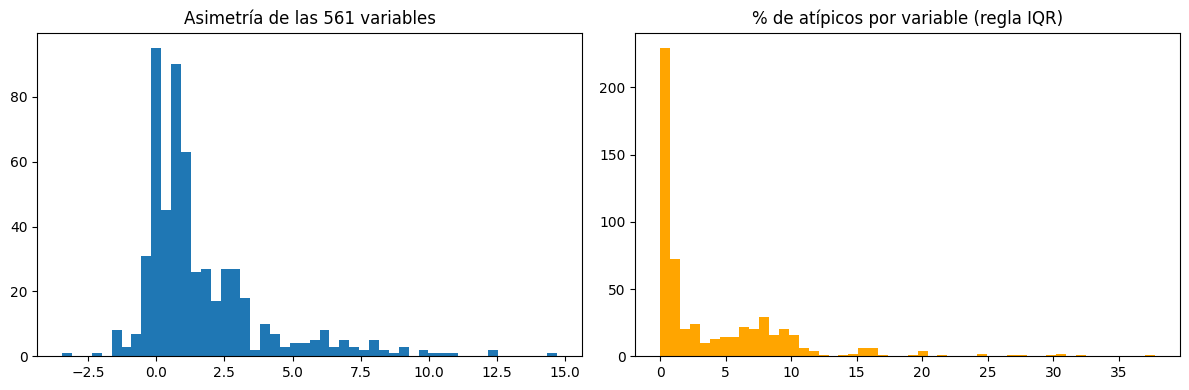

Variables con asimetría mayor a 1 (en valor absoluto): 277
Mediana de % de atípicos por variable: 1.2
Variable con más atípicos: tBodyAccJerk-mean()-X 37.8 %


In [9]:
asimetria = X_train.apply(skew)
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
es_atipico = (X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)
pct_atipicos = es_atipico.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(asimetria, bins=50)
axes[0].set_title("Asimetría de las 561 variables")
axes[1].hist(pct_atipicos, bins=50, color="orange")
axes[1].set_title("% de atípicos por variable (regla IQR)")
plt.tight_layout()
plt.show()

print("Variables con asimetría mayor a 1 (en valor absoluto):", (asimetria.abs() > 1).sum())
print("Mediana de % de atípicos por variable:", round(pct_atipicos.median(), 1))
print("Variable con más atípicos:", pct_atipicos.idxmax(), round(pct_atipicos.max(), 1), "%")

Casi la mitad de las variables son bastante asimétricas y algunas tienen más del 30% de valores "atípicos". Antes de eliminar algo quisimos ver **de qué actividades vienen esos atípicos**.

% de ventanas dinámicas en train: 44.7
% de todos los atípicos que son de ventanas dinámicas: 80.3

tBodyAccJerk-mean()-X: 37.8% atípicos. Actividad de esas ventanas:
actividad
WALKING               966
WALKING_DOWNSTAIRS    839
WALKING_UPSTAIRS      836
LAYING                 92
SITTING                30
STANDING               15

tGravityAcc-mean()-X: 20.0% atípicos. Actividad de esas ventanas:
actividad
LAYING              1407
SITTING               66
WALKING_UPSTAIRS       1


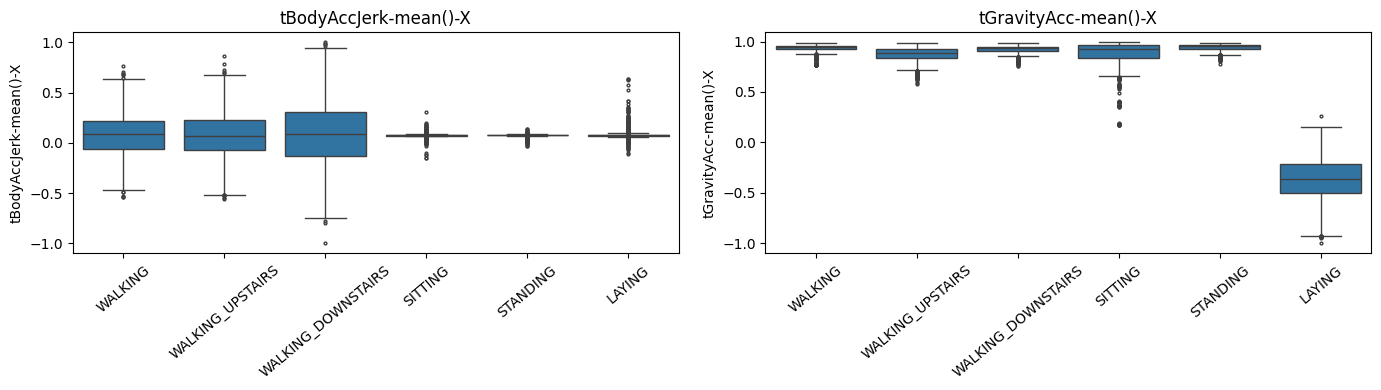

In [11]:
total_atipicos = es_atipico.values.sum()
atipicos_dinamica = es_atipico[info_train["grupo"] == "dinamica"].values.sum()
print("% de ventanas dinámicas en train:", round((info_train["grupo"] == "dinamica").mean() * 100, 1))
print("% de todos los atípicos que son de ventanas dinámicas:", round(atipicos_dinamica / total_atipicos * 100, 1))

ejemplos = ["tBodyAccJerk-mean()-X", "tGravityAcc-mean()-X"]
for v in ejemplos:
    print(f"\n{v}: {es_atipico[v].mean()*100:.1f}% atípicos. Actividad de esas ventanas:")
    print(info_train.loc[es_atipico[v], "actividad"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, v in zip(axes, ejemplos):
    sns.boxplot(x=info_train["actividad"], y=X_train[v], order=labels.tolist(), ax=ax, fliersize=2)
    ax.set_title(v)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()